# Hard-selection proximity and configuration changes


In [51]:
from scipy.special import logit

# PARAMETERS — edit here, then restart the kernel and run all cells.
d = 2_000                     # dimension
delta = 8.0                # total training sample size / dimension
rho = 0.01                  # probability of observing a label (realized fraction varies)
label_prior = 0.3           # P(Y = +1)
sigma = 1.0                 # Gaussian noise standard deviation
pi = 2.0                    # pseudo-label weight
penalty = 0.1               # ridge parameter
eta = 0.5                   # learning rate
T = 2_000                     # number of gradient updates
negative_margin = -logit(0.99)  # kappa_minus = -log(4)
positive_margin = logit(0.6)   # kappa_plus = log(4)
seed = 49
widths = [0.01, 0.05, 0.10] # positive widths in raw score units
checkpoints = [0, 10, 50, 100, 200, T] # state indices, inclusive of 0 and T

In [52]:
from pathlib import Path
import numpy as np
import sys
import torch
import matplotlib.pyplot as plt

root = Path.cwd().resolve()
if not (root / "src").is_dir():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.config import DataConfig, AlgorithmConfig
from src.dgp import IsotropicGaussian
from src.algorithms import SelfTrainedGradientDescent
from src.initialization import SelfTrainingInitialization, compute_scores
from src.primitives import pseudo_labels
from src.callbacks import TestEvaluatorCallback
from notebooks.experiment_helpers import exogenous_initial_labels

%matplotlib inline
widths = np.asarray(widths, dtype=float)
assert widths.ndim == 1 and widths.size > 0
assert np.all(np.isfinite(widths) & (widths > 0))
assert isinstance(T, int) and T >= 1
assert checkpoints and all(isinstance(t, int) and 0 <= t <= T for t in checkpoints)
checkpoints = sorted(set(checkpoints))
assert isinstance(d, int) and d > 0 and np.isfinite(sigma) and sigma >= 0

cfg = AlgorithmConfig(
    n_iterations=T, step_size=eta, penalty_param=penalty, pseudo_label_param=pi,
    negative_margin=negative_margin, positive_margin=positive_margin,
    normalized_threshold=False, normalize_unlabeled_loss=False,
    include_bias=True, initial_bias=0.0, bias_pseudo_label_param=0.0
)
data_cfg = DataConfig(
    scale=sigma, label_prior=label_prior, supervision_ratio=rho,
    data_to_dimension_ratio=delta, signal_law=lambda: 0.0,
)
# Same independent streams and initialization as run_experiment (Notebook 14).
rng = torch.Generator().manual_seed(seed + 11)
mu = torch.randn(d, generator=rng, dtype=torch.float64)
w_init = torch.randn(d, generator=rng, dtype=torch.float64)
dgp = IsotropicGaussian(data_cfg, n_train=round(delta * d), n_test=0,
                        dimensions=d, seed=seed + 23, signal_vector=mu)
environment, X, _, _ = dgp.sample_full()
assert environment.N > 0 and environment.M > 0, "Need labeled and unlabeled observations."
initialization = SelfTrainingInitialization(
    b_init=cfg.initial_bias, w_init=w_init,
    Y_init=exogenous_initial_labels(environment, torch.Generator().manual_seed(seed + 31)),
)
unlabeled = environment.I_U  # fixed observation order at every state
print(f"n={environment.n}, N={environment.N}, M={environment.M}, d={d}")


n=16000, N=180, M=15820, d=2000


For the same $M$ unlabeled training observations at every state,
$r_j^t=b^t+X_j^\top w^t/\sqrt d$ and
$$
m_j^t=\min\{|r_j^t-\kappa_-|,|r_j^t-\kappa_+|\},\qquad
A_t(\varepsilon)=M^{-1}\sum_j\mathbf1\{m_j^t\leq\varepsilon\}.
$$
Selection includes the boundaries: $r_j^t\leq\kappa_-$ or
$r_j^t\geq\kappa_+$. Define $\mathfrak P_j^t$ as the selected pseudo-label
($-1$ or $+1$), and zero when unselected. Then
$$
s^t=M^{-1}\sum_j\mathbf1\{\mathfrak P_j^{t+1}\ne\mathfrak P_j^t\}.
$$
This counts both selection-status changes and selected-label sign changes.
At $t=0$ the algorithm uses its exogenous initial pseudo-labels, not score
signs; thereafter it uses $\operatorname{sign}(r)$ with $\operatorname{sign}(0)=+1$.
Thus the first transition also reflects the initial label refresh.

States are indexed $0,\ldots,T$; switching rates are indexed $t=0,\ldots,T-1$
for transitions $t\to t+1$. The configuration at $T$ is evaluated without an
additional update. Thresholds act on **raw scores**, and the normalized
unlabeled loss divides selection weights by the empirical selection rate
(with zero contribution when none are selected). Logistic loss, ridge penalty,
bias updates, and update order are those of the existing implementation.


In [53]:
# Recreate the evaluator on every run so its scalar histories start empty.
callback = TestEvaluatorCallback(
    mu=environment.mu, sigma=data_cfg.scale, p=data_cfg.label_prior,
    metrics={"population_error"},
)

threshold_mass = np.empty((T + 1, len(widths)))
switching = np.empty(T)
checkpoint_scores = {}
previous_configuration = None
next_state = 0

@torch.no_grad()
def record(model, t):
    global previous_configuration, next_state
    assert t == next_state  # exactly one callback per state, in order
    callback(model, t)  # population error at the same state, including t=0 and t=T
    scores = compute_scores(X, model.bias, model.weights)[unlabeled]
    assert torch.isfinite(scores).all(), "Nonfinite scores; inspect the chosen parameters."
    configuration = (
        model.selection_mask(scores)
        * pseudo_labels(t, scores, model.initialization_.Y_init[unlabeled])
    ).numpy().astype(np.int8)
    assert np.isin(configuration, [-1, 0, 1]).all()
    values = scores.numpy()
    distance = np.minimum(np.abs(values - cfg.negative_margin),
                          np.abs(values - cfg.positive_margin))
    threshold_mass[t] = [np.mean(distance <= eps) for eps in widths]
    if previous_configuration is not None:
        switching[t - 1] = np.mean(configuration != previous_configuration)
    previous_configuration = configuration
    if t in checkpoints:
        checkpoint_scores[t] = values.copy()
    next_state += 1

    # The solver records each update by default. Discard it immediately;
    # these histories are diagnostics only and are never read by its update.
    model.update_records_.clear()
    model.score_history_.clear()
    model.weight_history_.clear()
    model.residual_history_.clear()
    model.prev_preactivations_ = None

model = SelfTrainedGradientDescent(cfg, callback=record)
model.fit_full(X, environment, initialization);

assert next_state == T + 1
assert threshold_mass.shape == (T + 1, len(widths)) and switching.shape == (T,)
assert set(checkpoint_scores) == set(checkpoints)
assert all(s.shape == (environment.M,) for s in checkpoint_scores.values())
for rates in (threshold_mass, switching):
    assert np.isfinite(rates).all() and np.all((0 <= rates) & (rates <= 1))
assert not any((model.update_records_, model.score_history_,
                model.weight_history_, model.residual_history_))
assert model.prev_preactivations_ is None
print(f"Verified {T + 1} states and {T} transitions; "
      f"{np.count_nonzero(switching == 0)} transitions have exactly zero switching.")


Verified 2001 states and 2000 transitions; 457 transitions have exactly zero switching.


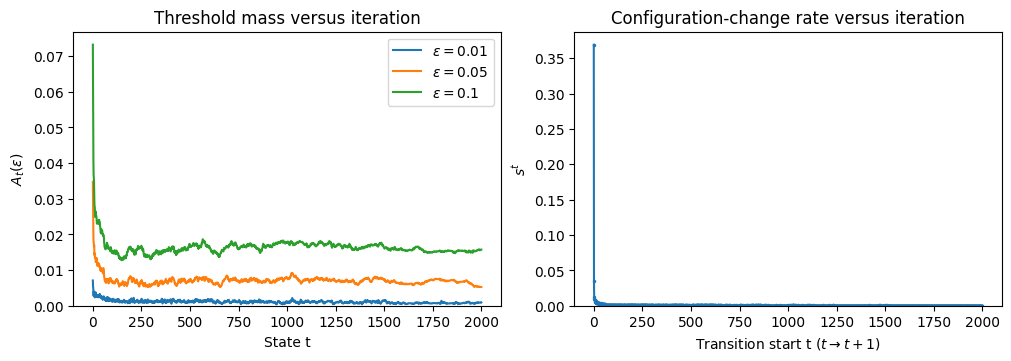

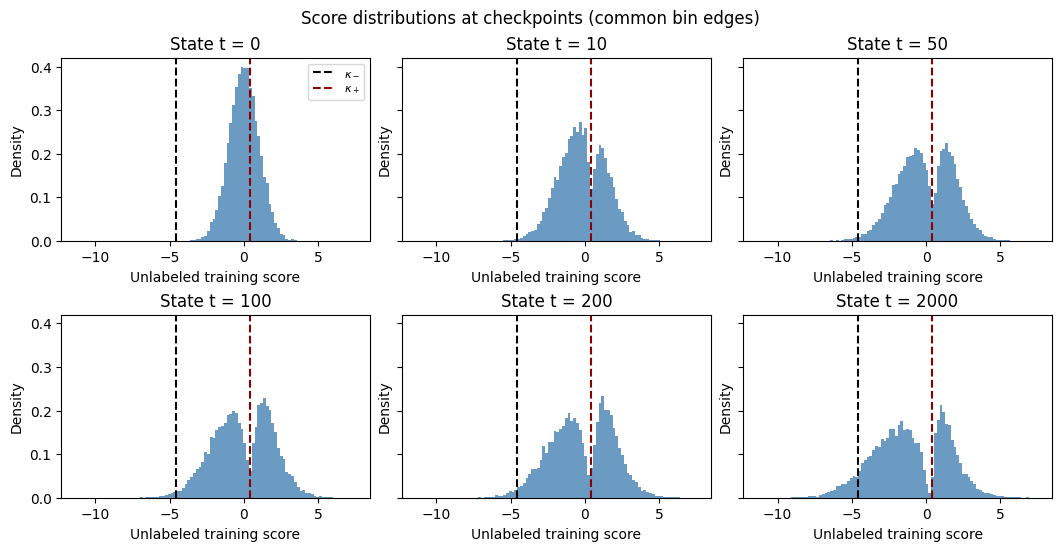

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for k, eps in enumerate(widths):
    axes[0].plot(np.arange(T + 1), threshold_mass[:, k], label=fr"$\varepsilon={eps:g}$")
axes[0].set(title="Threshold mass versus iteration", xlabel="State t",
            ylabel=r"$A_t(\varepsilon)$", ylim=(0, None))
axes[0].legend()
axes[1].plot(np.arange(T), switching, marker=".", markersize=3)
axes[1].set(title="Configuration-change rate versus iteration",
            xlabel=r"Transition start t ($t\to t+1$)", ylabel=r"$s^t$", ylim=(0, None))
# Linear scale and unmodified rates preserve exact zeros.
plt.show()

lo = min(cfg.negative_margin, min(s.min() for s in checkpoint_scores.values()))
hi = max(cfg.positive_margin, max(s.max() for s in checkpoint_scores.values()))
edges = np.linspace(lo - 0.02 * (hi - lo), hi + 0.02 * (hi - lo), 101)
ncols = min(3, len(checkpoints))
nrows = (len(checkpoints) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 2.7 * nrows),
                         squeeze=False, sharex=True, sharey=True, constrained_layout=True)
for ax, t in zip(axes.flat, checkpoints):
    ax.hist(checkpoint_scores[t], bins=edges, density=True, color="steelblue", alpha=0.8)
    ax.axvline(cfg.negative_margin, color="black", linestyle="--", label=r"$\kappa_-$")
    ax.axvline(cfg.positive_margin, color="darkred", linestyle="--", label=r"$\kappa_+$")
    ax.tick_params(labelbottom=True)
    ax.set(title=f"State t = {t}", xlabel="Unlabeled training score", ylabel="Density")
for ax in list(axes.flat)[len(checkpoints):]:
    ax.set_visible(False)
axes.flat[0].legend(fontsize=8)
fig.suptitle("Score distributions at checkpoints (common bin edges)")
plt.show()


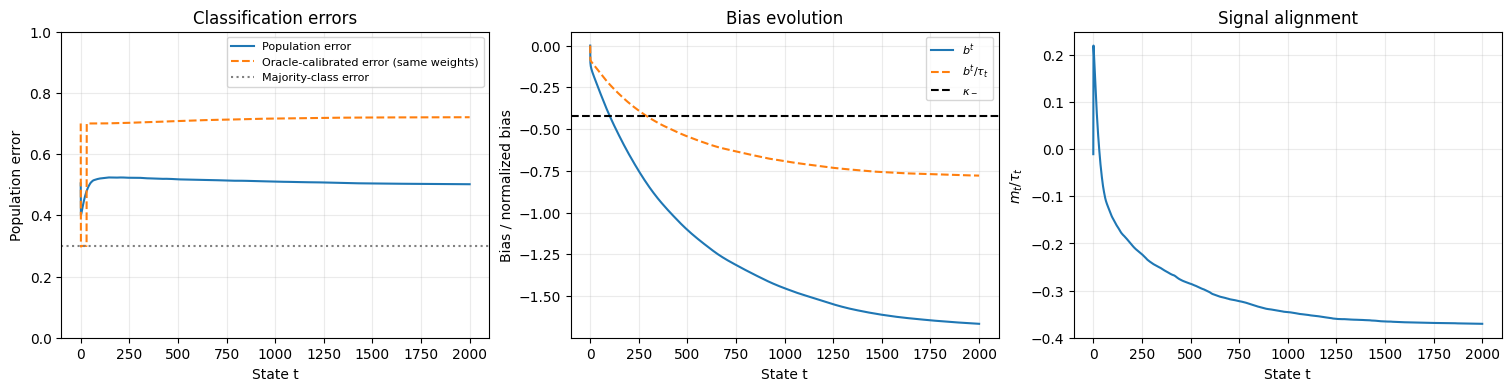

In [55]:
# Reuse scalar histories from the experiment above; no new fit is needed.
# tau_t = ||w_t|| / sqrt(d), m_t = <w_t, mu> / d.
history = callback.history_
population_error_history = np.asarray(history["population_error"], dtype=float)
oracle_error_history = np.asarray(history["oracle_error"], dtype=float)
bias_history = np.asarray(history["bias_term"], dtype=float)
weight_scale_history = np.asarray(history["weight_vector_norm"], dtype=float)
signal_overlap_history = np.asarray(history["weight_signal_alignment"], dtype=float)
for values in (population_error_history, oracle_error_history, bias_history,
               weight_scale_history, signal_overlap_history):
    assert values.shape == (T + 1,) and np.isfinite(values).all()
assert np.all((0 <= population_error_history) & (population_error_history <= 1))

# Undefined ratios at zero weight norm are left as NaN (gaps in the plots).
normalized_bias_history = np.divide(
    bias_history, weight_scale_history,
    out=np.full_like(bias_history, np.nan), where=weight_scale_history > 0,
)
signal_alignment_history = np.divide(
    signal_overlap_history, weight_scale_history,
    out=np.full_like(signal_overlap_history, np.nan), where=weight_scale_history > 0,
)

state_times = np.arange(T + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
axes[0].plot(state_times, population_error_history, label="Population error")
# Oracle error optimizes only the bias, holding the current weights fixed.
axes[0].plot(state_times, oracle_error_history, linestyle="--",
             label="Oracle-calibrated error (same weights)")
axes[0].axhline(min(data_cfg.label_prior, 1 - data_cfg.label_prior),
                color="gray", linestyle=":", label="Majority-class error")
axes[0].set(title="Classification errors", ylabel="Population error", ylim=(0, 1))
axes[0].legend(fontsize=8)

axes[1].plot(state_times, bias_history, label=r"$b^t$")
axes[1].plot(state_times, normalized_bias_history, linestyle="--",
             label=r"$b^t/\tau_t$")
axes[1].set(title="Bias evolution", ylabel="Bias / normalized bias")
axes[1].axhline(0.5 * sigma**2 * np.log(label_prior / (1 - label_prior)),
                color="black", linestyle="--", label=r"$\kappa_-$")
axes[1].legend(fontsize=8)

axes[2].plot(state_times, signal_alignment_history)
axes[2].set(title="Signal alignment", ylabel=r"$m_t/\tau_t$")
for ax in axes:
    ax.set_xlabel("State t")
    ax.grid(alpha=0.25)
plt.show()


## Late-time switching and long-window disagreement

For the realized unlabeled sample size $M$, the integer switch count is
$N_{\mathrm{switch}}^t=M s^t$ for transition $t\to t+1$.
The cumulative quantity $S(t)=\sum_{u=0}^{t-1}s^u$, with $S(0)=0$, counts
**cumulative switches per unlabeled observation**; it is not divided by time
and may exceed one. Endpoint disagreement
$h(s,t)=M^{-1}\sum_j\mathbf{1}\{\mathfrak P_j^s\ne\mathfrak P_j^t\}$
can miss observations that switch and later return, whereas cumulative
switching counts every change. All comparisons use the same unlabeled indices
in the same order and the existing selection and pseudo-label conventions.


In [44]:
# ADDITIONAL DIAGNOSTIC PARAMETERS
late_start = 50
disagreement_checkpoints = [100, 200, 400]

In [45]:
M = environment.M
assert isinstance(late_start, int) and late_start >= 0
assert all(isinstance(t, int) for t in disagreement_checkpoints)
valid_checkpoints = sorted({t for t in disagreement_checkpoints if 0 <= t <= T})
skipped_checkpoints = sorted(set(disagreement_checkpoints) - set(valid_checkpoints))
if skipped_checkpoints:
    print(f"Skipping checkpoints outside [0, {T}]: {skipped_checkpoints}")

# Recover integer counts from the existing rates (no new trajectory needed).
switch_counts = np.rint(switching * M).astype(np.int64)
assert switch_counts.shape == (T,) and np.issubdtype(switch_counts.dtype, np.integer)
assert np.all((0 <= switch_counts) & (switch_counts <= M))
np.testing.assert_allclose(switching * M, switch_counts, rtol=0, atol=1e-9)
np.testing.assert_array_equal(switch_counts / M, switching)
cumulative_switches = np.concatenate(([0.0], np.cumsum(switch_counts / M)))
assert cumulative_switches.shape == (T + 1,) and cumulative_switches[0] == 0
assert np.all(np.diff(cumulative_switches) >= 0)

# Reconstruct configurations directly from retained scores whenever possible.
configuration_checkpoints = {}
for t in valid_checkpoints:
    if t in checkpoint_scores:
        scores_at_t = torch.as_tensor(checkpoint_scores[t], dtype=X.dtype)
        configuration_checkpoints[t] = (
            cfg.selection_mask(scores_at_t)
            * pseudo_labels(t, scores_at_t, model.initialization_.Y_init[unlabeled])
        ).numpy().astype(np.int8).copy()
if T in valid_checkpoints:
    configuration_checkpoints[T] = previous_configuration.copy()

missing_checkpoints = set(valid_checkpoints) - set(configuration_checkpoints)
if missing_checkpoints:
    print(f"Replaying the same run for missing configurations: {sorted(missing_checkpoints)}")
    replay_next_state = 0

    @torch.no_grad()
    def record_missing_configuration(replay_model, t):
        global replay_next_state
        assert t == replay_next_state
        replay_next_state += 1
        if t in missing_checkpoints:
            scores_at_t = compute_scores(X, replay_model.bias, replay_model.weights)[unlabeled]
            configuration_checkpoints[t] = (
                replay_model.selection_mask(scores_at_t)
                * pseudo_labels(t, scores_at_t, replay_model.initialization_.Y_init[unlabeled])
            ).numpy().astype(np.int8).copy()
        replay_model.update_records_.clear()
        replay_model.score_history_.clear()
        replay_model.weight_history_.clear()
        replay_model.residual_history_.clear()
        replay_model.prev_preactivations_ = None

    replay_model = SelfTrainedGradientDescent(cfg, callback=record_missing_configuration)
    replay_model.fit_full(X, environment, initialization)
    assert replay_next_state == T + 1
    assert torch.equal(replay_model.weights, model.weights)
    assert torch.equal(replay_model.bias, model.bias)
    del replay_model
else:
    print("Reused retained scores/configurations; no replay needed.")

assert set(configuration_checkpoints) == set(valid_checkpoints)
assert torch.equal(unlabeled, environment.I_U)
for configuration in configuration_checkpoints.values():
    assert configuration.shape == (M,) and np.isin(configuration, [-1, 0, 1]).all()

disagreement_rows = []
for i, s in enumerate(valid_checkpoints):
    for t in valid_checkpoints[i + 1:]:
        count = int(np.count_nonzero(configuration_checkpoints[s] != configuration_checkpoints[t]))
        fraction = count / M
        assert 0 <= s < t <= T and 0 <= count <= M and 0 <= fraction <= 1
        disagreement_rows.append((s, t, count, fraction))
print(f"Checked {T} integer transition counts, {T + 1} cumulative states, "
      f"and {len(disagreement_rows)} checkpoint pairs; M={M}.")


Replaying the same run for missing configurations: [400]
Checked 2000 integer transition counts, 2001 cumulative states, and 3 checkpoint pairs; M=15820.


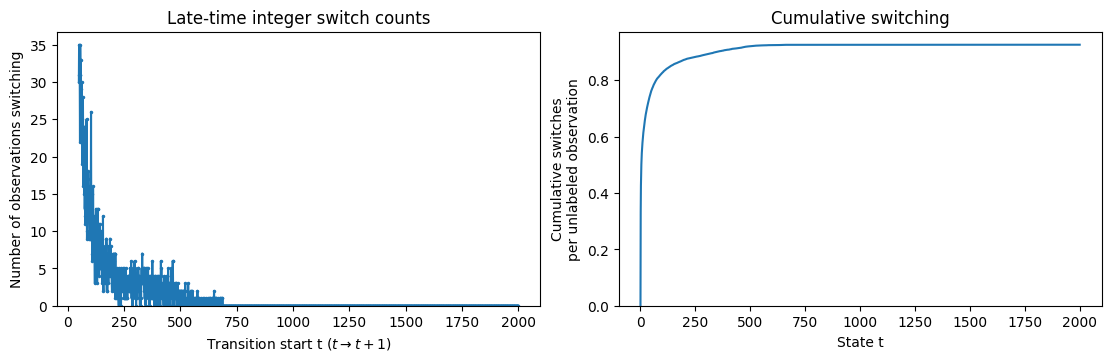

Long-window configuration disagreement
     s      t   Different observations       h(s,t)
   100    200                      722   0.04556930
   100    400                     1285   0.08110326
   200    400                      567   0.03578642


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
transition_times = np.arange(T)
late = transition_times >= late_start
axes[0].plot(transition_times[late], switch_counts[late], marker=".", markersize=3)
axes[0].set(title="Late-time integer switch counts", xlabel=r"Transition start t ($t\to t+1$)",
            ylabel="Number of observations switching", ylim=(0, None))
if not late.any():
    axes[0].text(0.5, 0.5, "No transitions in the requested late window",
                 transform=axes[0].transAxes, ha="center", wrap=True)
axes[1].plot(np.arange(T + 1), cumulative_switches)
axes[1].set(title="Cumulative switching", xlabel="State t",
            ylabel="Cumulative switches\nper unlabeled observation", ylim=(0, None))
plt.show()

# A plain text table needs no additional display or dataframe dependency.
print("Long-window configuration disagreement")
print(f"{'s':>6} {'t':>6} {'Different observations':>24} {'h(s,t)':>12}")
for s, t, count, fraction in disagreement_rows:
    print(f"{s:6d} {t:6d} {count:24d} {fraction:12.8f}")
if not disagreement_rows:
    print("Fewer than two valid checkpoints; no pairs to compare.")
